In [1]:
import cv2
import matplotlib.pyplot as plt
import torch
import torchinfo

In [2]:
from generate_image import generate_image
from generate_noise import noise_add, noise_mul
from generate_dataset import generate_dataset, NoiseType

#### Generiranje slik - Trioktniki

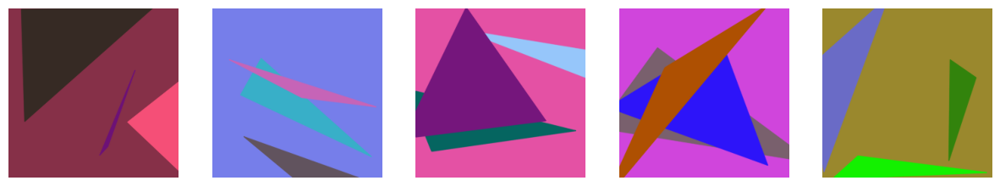

In [3]:
fig, ax_table = plt.subplots(1, 5, figsize=(15, 3))
for ax in ax_table.ravel():
    img = generate_image(256, 256, 3, 0, 0, 0)
    ax.imshow(img)
    ax.set_axis_off()

#### Generiranje slik - Štirikotniki

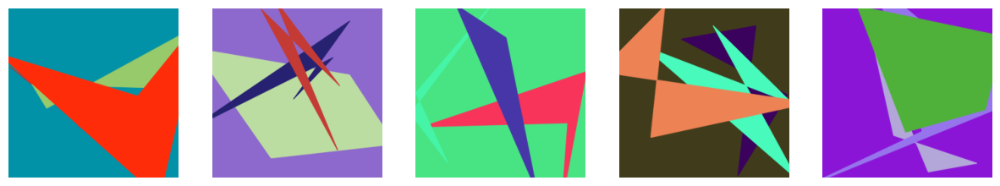

In [4]:
fig, ax_table = plt.subplots(1, 5, figsize=(15, 3))
for ax in ax_table.ravel():
    img = generate_image(256, 256, 0, 3, 0, 0)
    ax.imshow(img)
    ax.set_axis_off()

#### Generiranje slik - Elipse

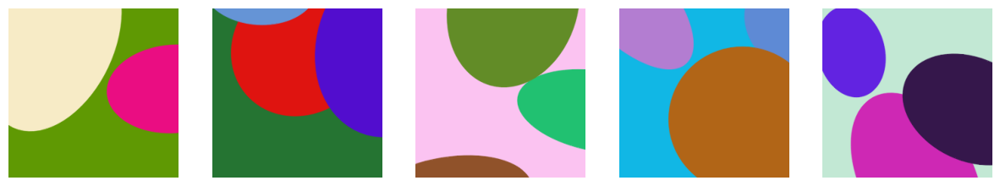

In [5]:
fig, ax_table = plt.subplots(1, 5, figsize=(15, 3))
for ax in ax_table.ravel():
    img = generate_image(256, 256, 0, 0, 3, 0)
    ax.imshow(img)
    ax.set_axis_off()

#### Generiranje slik - Zvezde

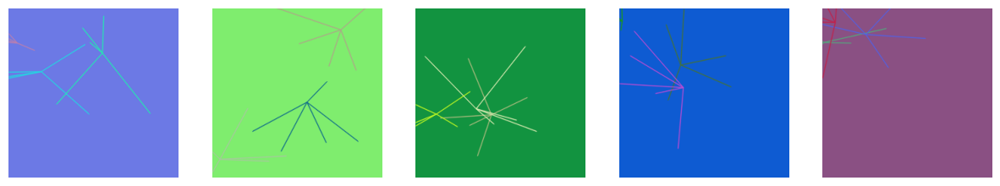

In [6]:
fig, ax_table = plt.subplots(1, 5, figsize=(15, 3))
for ax in ax_table.ravel():
    img = generate_image(256, 256, 0, 0, 0, 3)
    ax.imshow(img)
    ax.set_axis_off()

#### Učni primerki

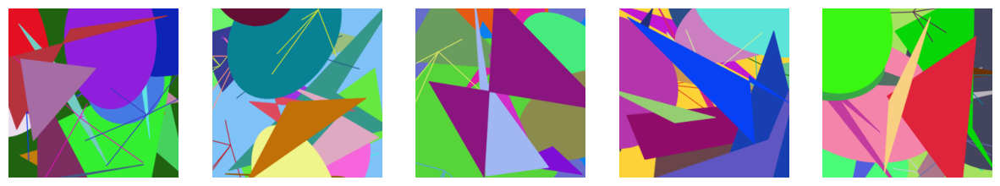

In [7]:
fig, ax_table = plt.subplots(1, 5, figsize=(15, 3))
for ax in ax_table.ravel():
    img = generate_image(256, 256, 5, 5, 5, 5)
    ax.imshow(img)
    ax.set_axis_off()

#### Generiranje šuma

(-0.5, 255.5, 255.5, -0.5)

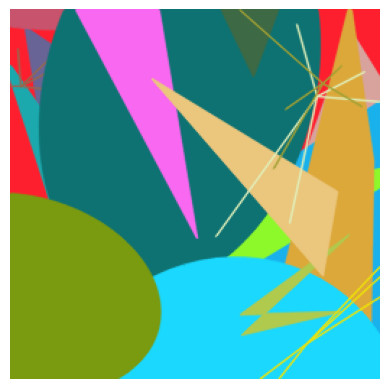

In [8]:
img = generate_image(256, 256, 5, 5, 5, 5)
plt.imshow(img)
plt.axis('off')

#### Generiranje šuma - Aditivni šum

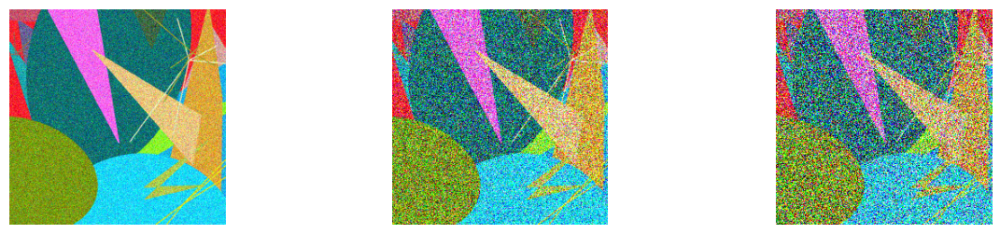

In [9]:
fig, ax_table = plt.subplots(1, 3, figsize=(15,3))
for ax, std in zip(ax_table.ravel(), [0.1, 0.3, 0.5]):
    img_add = noise_add(img, std)
    ax.imshow(img_add)
    ax.set_axis_off()

#### Generiranje šuma - Multiplikativni šum

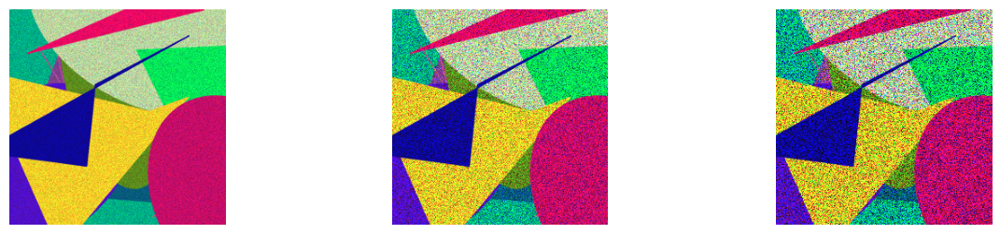

In [17]:
fig, ax_table = plt.subplots(1, 3, figsize=(15,3))
for ax, std in zip(ax_table.ravel(), [0.1, 0.3, 0.5]):
    img_mul = noise_mul(img, std)
    ax.imshow(img_mul)
    ax.set_axis_off()

#### Generiranje slik z obema tipoma šuma

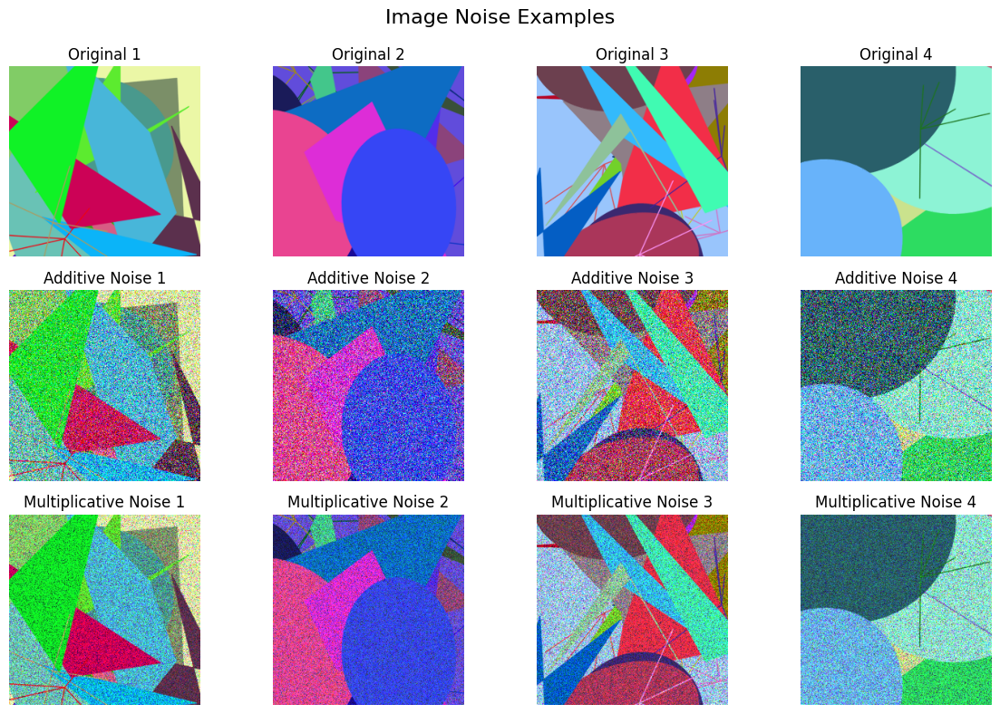

In [10]:
# Generate images
original_images = [generate_image() for _ in range(4)]

# Add noise
additive_noisy_images = [noise_add(img, std=0.3) for img in original_images]
multiplicative_noisy_images = [noise_mul(img, std=0.3) for img in original_images]

# Define rows: (row title, image list)
rows = [
    ("Original", original_images),
    ("Additive Noise", additive_noisy_images),
    ("Multiplicative Noise", multiplicative_noisy_images),
]

# Plot
fig, axs = plt.subplots(nrows=3, ncols=4, figsize=(12, 8))
fig.suptitle("Image Noise Examples", fontsize=16)

for row_idx, (title, images) in enumerate(rows):
    for col_idx, img in enumerate(images):
        ax = axs[row_idx, col_idx]
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{title} {col_idx + 1}")
        ax.axis("off")

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

In [11]:
# Nevronska mreža
from neural_network import *

#### Inicializacija modela in izpis strukture - Aditivni šum

In [13]:
# Model
model_add = EPSFilterNet(n_filts=8)
optimizer = torch.optim.Adam(model_add.parameters(), lr=1e-3)
loss_fn = torch.nn.MSELoss()
noise_fn = noise_add # noise_add ali noise_mul
model_file_name = f"model_{noise_fn.__name__}.pt"

print(torchinfo.summary(model_add, [1, 3, 256, 256]))

Layer (type:depth-idx)                   Output Shape              Param #
EPSFilterNet                             [1, 3, 256, 256]          --
├─FilterBranch: 1-1                      [1, 8, 256, 256]          --
│    └─Conv2d: 2-1                       [1, 8, 256, 256]          968
│    └─Conv2d: 2-2                       [1, 8, 256, 256]          968
│    └─Conv2d: 2-3                       [1, 8, 256, 256]          968
├─ClasificationBranch: 1-2               [1, 8, 256, 256]          --
│    └─ResNetBlock: 2-4                  [1, 32, 256, 256]         --
│    │    └─Conv2d: 3-1                  [1, 32, 256, 256]         896
│    │    └─BatchNorm2d: 3-2             [1, 32, 256, 256]         64
│    │    └─Dropout2d: 3-3               [1, 32, 256, 256]         --
│    │    └─ReLU: 3-4                    [1, 32, 256, 256]         --
│    │    └─Conv2d: 3-5                  [1, 32, 256, 256]         9,248
│    │    └─BatchNorm2d: 3-6             [1, 32, 256, 256]         64
│    │  

#### Generiranje učne množice - Aditivni šum

In [14]:
generate_dataset(5000, NoiseType.ADDITIVE)

Generating images....
Saving dataset in train_dataset_add.pt file
Dataset saved


#### Učenje nevronske mreže in shranevanje modela - Aditivni šum

In [15]:
# Učenje
epochs = 30
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Device: {device}")
nn_train(model=model_add, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs, noise_fn=noise_fn, batch_size=16, device=device)
torch.save(model_add, model_file_name)

Device: cpu
Epoch [1/30], Loss: 0.013702791373129375
Epoch [2/30], Loss: 0.005403969625826365
Epoch [3/30], Loss: 0.004732916825644362
Epoch [4/30], Loss: 0.004470650129728376
Epoch [5/30], Loss: 0.004163974602989401
Epoch [6/30], Loss: 0.003909784761189034
Epoch [7/30], Loss: 0.0037047560973920094
Epoch [8/30], Loss: 0.003544126516773392
Epoch [9/30], Loss: 0.00340956710159969
Epoch [10/30], Loss: 0.003283886381011373
Epoch [11/30], Loss: 0.0031856242120980073
Epoch [12/30], Loss: 0.003097614071096856
Epoch [13/30], Loss: 0.0030366186686336233
Epoch [14/30], Loss: 0.0029684952259385073
Epoch [15/30], Loss: 0.0029358480002183596
Epoch [16/30], Loss: 0.0028633481641404165
Epoch [17/30], Loss: 0.0028133893143028593
Epoch [18/30], Loss: 0.0027736224235591894
Epoch [19/30], Loss: 0.002760706118682917
Epoch [20/30], Loss: 0.0027086545840447275
Epoch [21/30], Loss: 0.0026798767153733073
Epoch [22/30], Loss: 0.0026642258164469904
Epoch [23/30], Loss: 0.002643149893599958
Epoch [24/30], Loss: 

#### Inicializacija modela in izpis strukture - Multiplikatvini šum

In [6]:
model_mul = EPSFilterNet(n_filts=8)
optimizer = torch.optim.Adam(model_mul.parameters(), lr=1e-3)
loss_fn = torch.nn.MSELoss()
noise_fn = noise_mul # noise_add ali noise_mul
model_file_name = f"model_{noise_fn.__name__}.pt"

print(torchinfo.summary(model_mul, [1, 3, 256, 256]))

Layer (type:depth-idx)                   Output Shape              Param #
EPSFilterNet                             [1, 3, 256, 256]          --
├─FilterBranch: 1-1                      [1, 8, 256, 256]          --
│    └─Conv2d: 2-1                       [1, 8, 256, 256]          968
│    └─Conv2d: 2-2                       [1, 8, 256, 256]          968
│    └─Conv2d: 2-3                       [1, 8, 256, 256]          968
├─ClasificationBranch: 1-2               [1, 8, 256, 256]          --
│    └─ResNetBlock: 2-4                  [1, 32, 256, 256]         --
│    │    └─Conv2d: 3-1                  [1, 32, 256, 256]         896
│    │    └─BatchNorm2d: 3-2             [1, 32, 256, 256]         64
│    │    └─Dropout2d: 3-3               [1, 32, 256, 256]         --
│    │    └─ReLU: 3-4                    [1, 32, 256, 256]         --
│    │    └─Conv2d: 3-5                  [1, 32, 256, 256]         9,248
│    │    └─BatchNorm2d: 3-6             [1, 32, 256, 256]         64
│    │  

#### Generiranje učne množice - Multiplikativni šum

In [17]:
generate_dataset(5000, NoiseType.MULTIPLICATIVE)

Generating images....
Saving dataset in train_dataset_mult.pt file
Dataset saved


#### Učenje nevronske mreže in shranevanje modela - Multiplikatvini šum

In [7]:
# Učenje
epochs = 30
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Device: {device}")
nn_train(model=model_mul, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs, noise_fn=noise_fn, batch_size=16, device=device)
torch.save(model_mul, model_file_name)

Device: cpu
Epoch [1/30], Loss: 0.012503098409337263
Epoch [2/30], Loss: 0.0037329664569907485
Epoch [3/30], Loss: 0.00297811417914808
Epoch [4/30], Loss: 0.0025714154611118493
Epoch [5/30], Loss: 0.0023183483826056026
Epoch [6/30], Loss: 0.002160632848953858
Epoch [7/30], Loss: 0.0020195288184179237
Epoch [8/30], Loss: 0.001905636248601297
Epoch [9/30], Loss: 0.0018202885665511265
Epoch [10/30], Loss: 0.0017477158291902119
Epoch [11/30], Loss: 0.0016800134633176815
Epoch [12/30], Loss: 0.0016330840838210175
Epoch [13/30], Loss: 0.0015879896593640169
Epoch [14/30], Loss: 0.0015074136777046008
Epoch [15/30], Loss: 0.001439568422624645
Epoch [16/30], Loss: 0.0013567861292314845
Epoch [17/30], Loss: 0.0012928766091339313
Epoch [18/30], Loss: 0.0012269592226539462
Epoch [19/30], Loss: 0.0011973515881549793
Epoch [20/30], Loss: 0.0011541250101573313
Epoch [21/30], Loss: 0.0011290206453768898
Epoch [22/30], Loss: 0.0010946619487293184
Epoch [23/30], Loss: 0.0010879284169632024
Epoch [24/30],

#### Nalaganje shranjenega modela - Adtivni šum

In [12]:
noise_fn = noise_add # noise_add ali noise_mul
model_file_name = f"model_{noise_fn.__name__}.pt"
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

model_add_l = torch.load(model_file_name, map_location=torch.device('cpu'), weights_only=False)
model_add_l.eval()
model_add_l.to(device)

EPSFilterNet(
  (filterBranch): FilterBranch(
    (filter_conv_r): Conv2d(1, 8, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
    (filter_conv_g): Conv2d(1, 8, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
    (filter_conv_b): Conv2d(1, 8, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
  )
  (classificationBranch): ClasificationBranch(
    (resNetBlock_1): ResNetBlock(
      (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (dropout1): Dropout2d(p=0.5, inplace=False)
      (relu1): ReLU(inplace=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (dropout2): Dropout2d(p=0.5, inplace=False)
      (relu2): ReLU(inplace=True)
    )
    (resNetBlock_2): ResNetBlock(
      (conv1): Co

#### Testiranje nevronske mreže - Aditivni šum

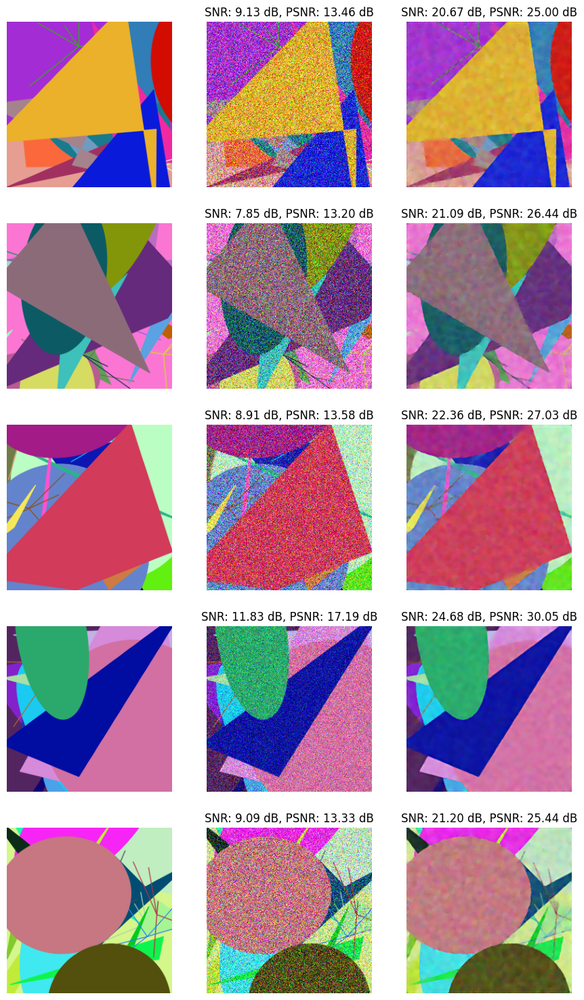

In [13]:
num_of_tests = 5
fig, ax = plt.subplots(nrows=num_of_tests, ncols=3, figsize=(9, 3*num_of_tests))

for i in range(0, num_of_tests):
    img, img_noise, img_filt, snr_noise, psnr_noise, snr_filt, psnr_filt= nn_test(model_add_l, NoiseType.ADDITIVE, device)

    ax[i, 0].imshow(img)
    ax[i, 1].imshow(img_noise)
    ax[i, 2].imshow(img_filt)
    ax[i, 1].set_title(f"SNR: {snr_noise:.2f} dB, PSNR: {psnr_noise:.2f} dB")
    ax[i, 2].set_title(f"SNR: {snr_filt:.2f} dB, PSNR: {psnr_filt:.2f} dB")
    
    plt.tight_layout()

for ax in fig.get_axes():
    ax.set_axis_off()

#### Nalaganje shranjenega modela - Multiplikativni šum

In [14]:
noise_fn = noise_mul # noise_add ali noise_mul
model_file_name = f"model_{noise_fn.__name__}.pt"
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

model_mul_l = torch.load(model_file_name, map_location=torch.device('cpu'), weights_only=False)
model_mul_l.eval()
model_mul_l.to(device)

EPSFilterNet(
  (filterBranch): FilterBranch(
    (filter_conv_r): Conv2d(1, 8, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
    (filter_conv_g): Conv2d(1, 8, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
    (filter_conv_b): Conv2d(1, 8, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
  )
  (classificationBranch): ClasificationBranch(
    (resNetBlock_1): ResNetBlock(
      (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (dropout1): Dropout2d(p=0.5, inplace=False)
      (relu1): ReLU(inplace=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (dropout2): Dropout2d(p=0.5, inplace=False)
      (relu2): ReLU(inplace=True)
    )
    (resNetBlock_2): ResNetBlock(
      (conv1): Co

#### Testiranje nevronske mreže - Multiplikativni šum

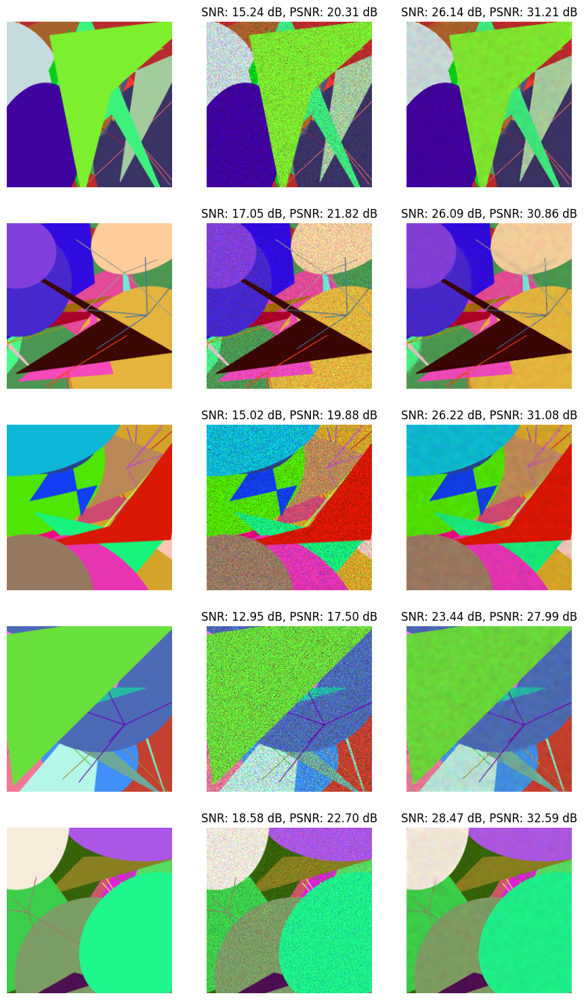

In [15]:
num_of_tests = 5
fig, ax = plt.subplots(nrows=num_of_tests, ncols=3, figsize=(9, 3*num_of_tests))

for i in range(0, num_of_tests):
    img, img_noise, img_filt, snr_noise, psnr_noise, snr_filt, psnr_filt= nn_test(model_mul_l, NoiseType.MULTIPLICATIVE, device)

    ax[i, 0].imshow(img)
    ax[i, 1].imshow(img_noise)
    ax[i, 2].imshow(img_filt)
    ax[i, 1].set_title(f"SNR: {snr_noise:.2f} dB, PSNR: {psnr_noise:.2f} dB")
    ax[i, 2].set_title(f"SNR: {snr_filt:.2f} dB, PSNR: {psnr_filt:.2f} dB")
    
    plt.tight_layout()

for ax in fig.get_axes():
    ax.set_axis_off()

#### Naučeni filtri mreže za odstranjevanje aditivnega šuma

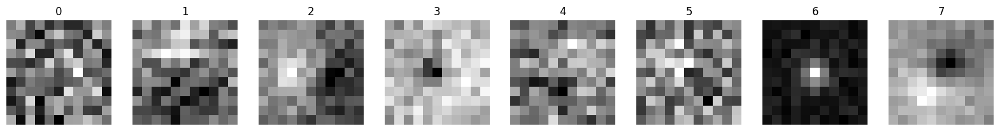

In [6]:
# Nalaganje modela
model = torch.load('model_noise_add.pt', map_location=torch.device('cpu'), weights_only=False)

# Izbira uteži filtrov
filters_r = model.filterBranch.filter_conv_r.weight.detach().numpy()
filters_g = model.filterBranch.filter_conv_g.weight.detach().numpy()
filters_b = model.filterBranch.filter_conv_b.weight.detach().numpy()

filters = np.concatenate([filters_r, filters_g, filters_b], axis=1)

N = filters.shape[0]
fig, ax = plt.subplots(1, N, figsize=(N * 2.5, 3))
for n in range(N):
    ax[n].set_title(f'{n}')
    ax[n].imshow(filters[n, 0], cmap='gray')
    ax[n].set_axis_off()

#### Naučeni filtri mreže za odstranjevanje multiplikativnega šuma

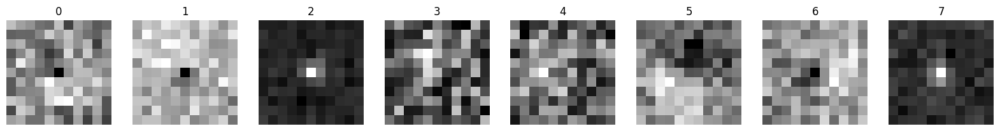

In [7]:
# Nalaganje modela
model = torch.load('model_noise_mul.pt', map_location=torch.device('cpu'), weights_only=False)

# Izbira uteži filtrov
filters_r = model.filterBranch.filter_conv_r.weight.detach().numpy()
filters_g = model.filterBranch.filter_conv_g.weight.detach().numpy()
filters_b = model.filterBranch.filter_conv_b.weight.detach().numpy()

filters = np.concatenate([filters_r, filters_g, filters_b], axis=1)

N = filters.shape[0]
fig, ax = plt.subplots(1, N, figsize=(N * 2.5, 3))
for n in range(N):
    ax[n].set_title(f'{n}')
    ax[n].imshow(filters[n, 0], cmap='gray')
    ax[n].set_axis_off()

#### Rezultati filtriranja - Aditivni šum

In [8]:
# Ovrednotenje
iterations = 1000
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# Nalaganje modela
model_add = torch.load('model_noise_add.pt', map_location=torch.device('cpu'), weights_only=False)
model_add.eval()
model_add.to(device)
nn_eval(model_add, iterations, NoiseType.ADDITIVE, device)

SNR (noisy): 10.67 ± 2.67 dB
PSNR (noisy): 15.60 ± 2.45 dB
SNR (filtered): 22.45 ± 2.40 dB
PSNR (filtered): 27.38 ± 2.16 dB


#### Rezultati filtriranja - Multiplikativni šum

In [9]:
# Ovrednotenje
iterations = 1000
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# Nalaganje modela
model_mul = torch.load('model_noise_mul.pt', map_location=torch.device('cpu'), weights_only=False)
model_mul.eval()
model_mul.to(device)
nn_eval(model_mul, iterations, NoiseType.MULTIPLICATIVE, device)

SNR (noisy): 15.30 ± 2.50 dB
PSNR (noisy): 20.21 ± 2.61 dB
SNR (filtered): 25.51 ± 2.27 dB
PSNR (filtered): 30.42 ± 2.54 dB


#### Slika 1 - Rezultati odstranjevanja aditivnega šuma na fotografijah

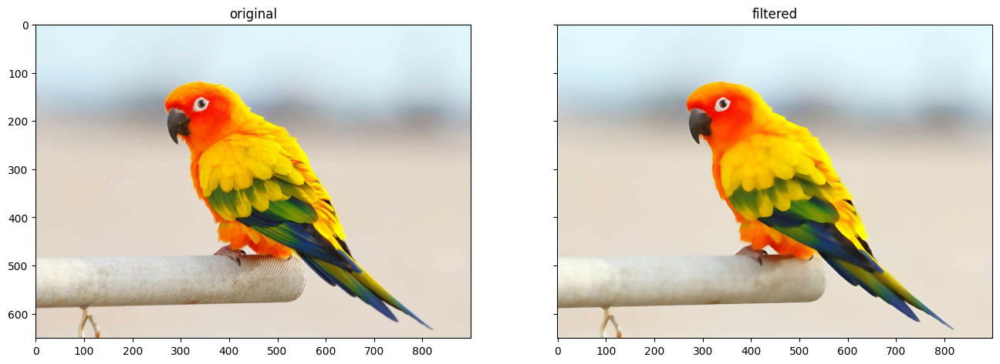

In [10]:
model_add = torch.load('model_noise_add.pt', map_location=torch.device('cpu'), weights_only=False)
model_add.eval()
model_add.to(device)
img = plt.imread('./bird1.jpg')

img_tr = torch.from_numpy(np.float32(img/255.).transpose(2, 0, 1)[np.newaxis])
pred_list = model_add(img_tr)

img_filt = pred_list[0].detach().numpy().transpose(1, 2, 0)
img_filt = np.uint8(np.clip(img_filt, 0, 1)*255)

fig, ax_table = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax, s, t in zip(ax_table.ravel(), [img, img_filt], ['original', 'filtered']):
    ax.imshow(s)
    ax.set_title(t)

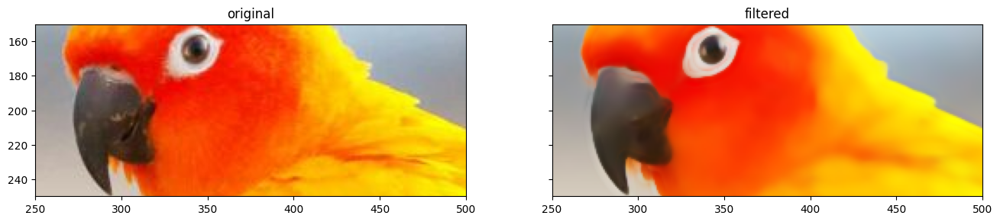

In [11]:
ax_table[0].set_xlim(250, 500)
ax_table[0].set_ylim(250, 150)
fig

#### Uteži uporabljene za združevanje filtrov

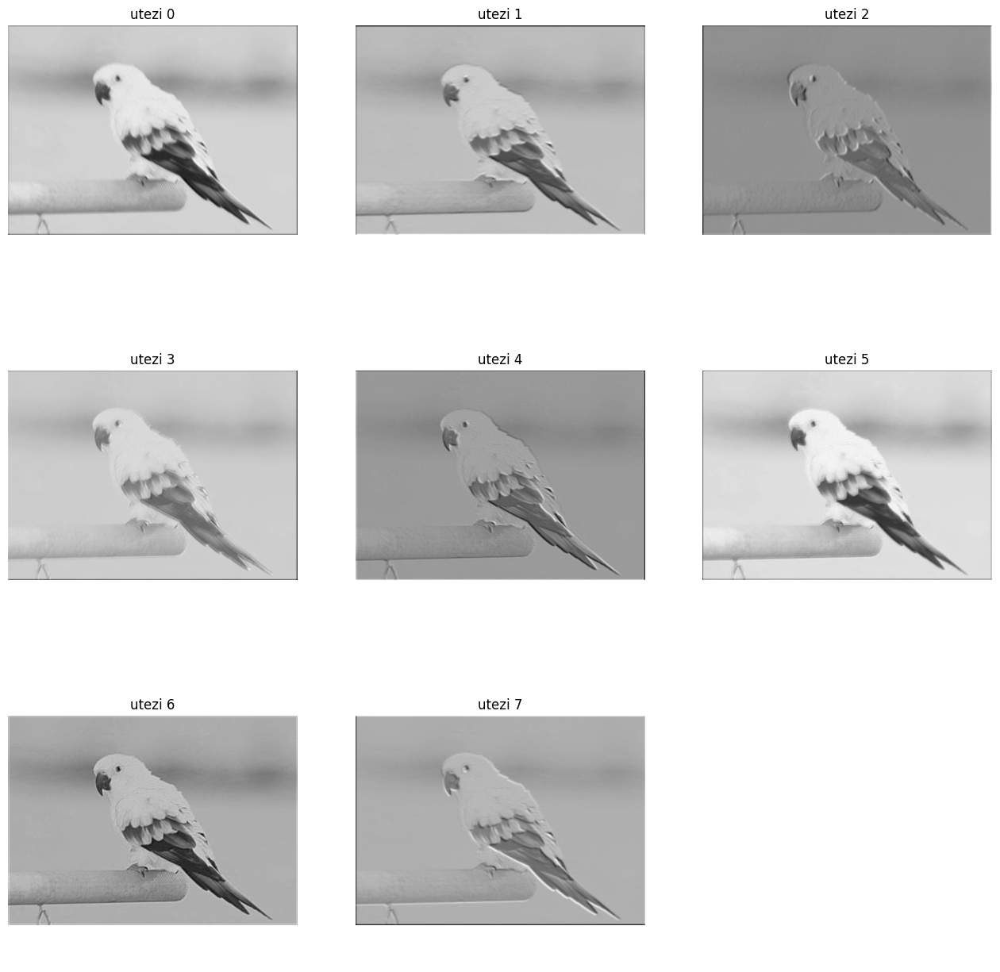

In [12]:
# Uteži
activation = {}

model_add.filterBranch.filter_conv_r.register_forward_hook(
    lambda model, input, output: activation.update({"filter_conv_r": output.detach()})
)

predictions = model_add(img_tr)
feature_maps = activation["filter_conv_r"].numpy()[0]

fig, ax_table = plt.subplots(3, 3, figsize=(16, 16), sharex=True, sharey=True)
ax_table = ax_table.ravel()

for n in range(8):
    ax_table[n].imshow(feature_maps[n], cmap='gray')
    ax_table[n].set_title(f'utezi {n}')
    ax_table[n].set_axis_off()

ax_table[8].set_axis_off()
plt.show()

#### Slika 2 - Rezultati odstranjevanja multiplikativnega šuma na fotografijah

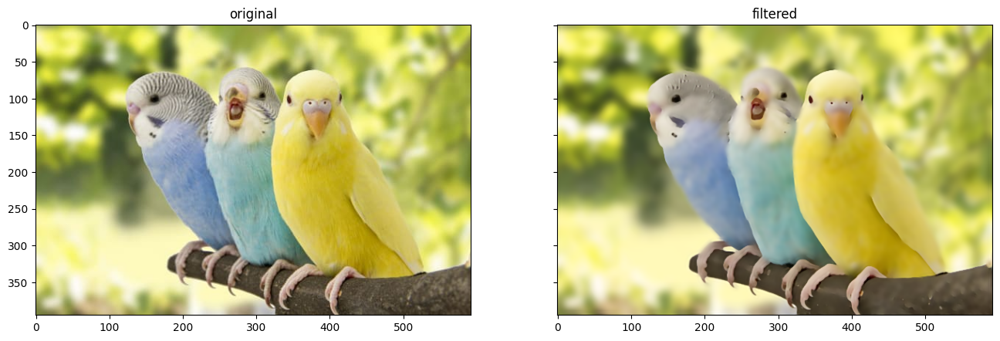

In [13]:
model_mul = torch.load('model_noise_mul.pt', map_location=torch.device('cpu'), weights_only=False)
model_mul.eval()
model_mul.to(device)
img = plt.imread('./bird2.jpeg')

img_tr = torch.from_numpy(np.float32(img/255.).transpose(2, 0, 1)[np.newaxis])
pred_list = model_mul(img_tr)

img_filt = pred_list[0].detach().numpy().transpose(1, 2, 0)
img_filt = np.uint8(np.clip(img_filt, 0, 1)*255)

fig, ax_table = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax, s, t in zip(ax_table.ravel(), [img, img_filt], ['original', 'filtered']):
    ax.imshow(s)
    ax.set_title(t)

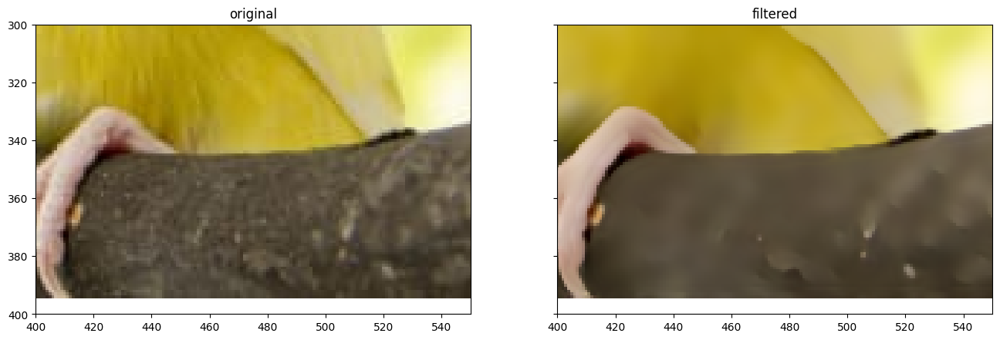

In [14]:
ax_table[0].set_xlim(400, 550)
ax_table[0].set_ylim(400, 300)

fig

#### Uteži uporabljene za združevanje filtrov

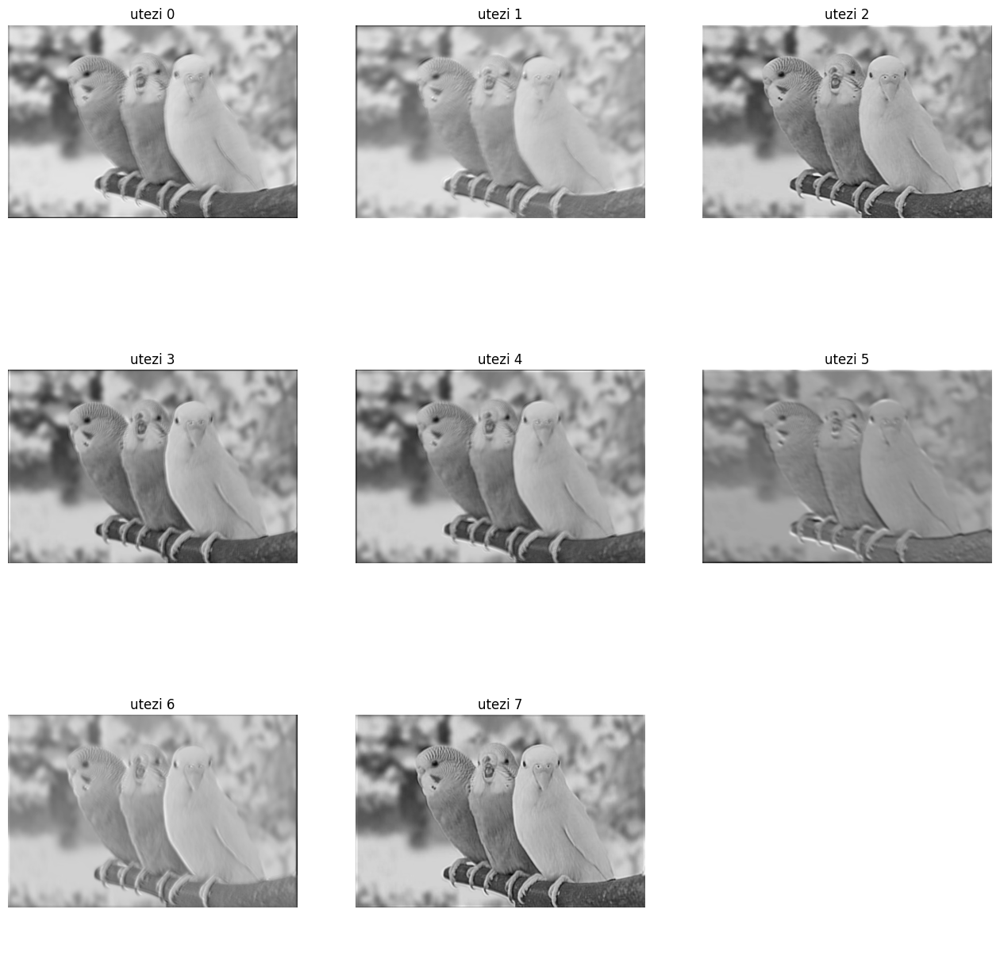

In [15]:
# Uteži
activation = {}

model_mul.filterBranch.filter_conv_r.register_forward_hook(
    lambda model, input, output: activation.update({"filter_conv_r": output.detach()})
)

predictions = model_mul(img_tr)
feature_maps = activation["filter_conv_r"].numpy()[0]

fig, ax_table = plt.subplots(3, 3, figsize=(16, 16), sharex=True, sharey=True)
ax_table = ax_table.ravel()

for n in range(8):
    ax_table[n].imshow(feature_maps[n], cmap='gray')
    ax_table[n].set_title(f'utezi {n}')
    ax_table[n].set_axis_off()

ax_table[8].set_axis_off()
plt.show()

#### Slika 3 - Rezultati odstranjevanja aditivnega in multiplikativnega šuma na fotografijah

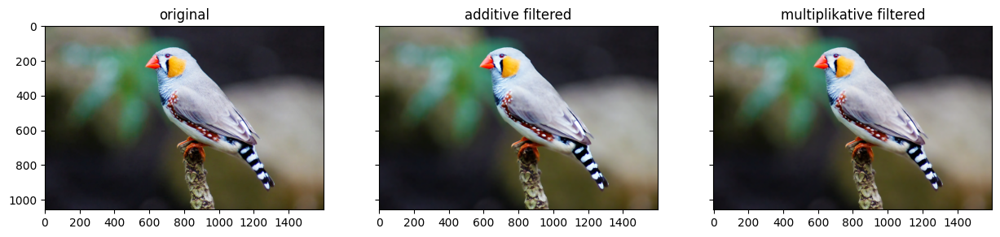

In [16]:
img = plt.imread('./bird3.webp')

img_tr = torch.from_numpy(np.float32(img/255.).transpose(2, 0, 1)[np.newaxis])

pred_list = model_add(img_tr)
img_filt_a = pred_list[0].detach().numpy().transpose(1, 2, 0)
img_filt_a = np.uint8(np.clip(img_filt_a, 0, 1)*255)

pred_list = model_mul(img_tr)
img_filt_m = pred_list[0].detach().numpy().transpose(1, 2, 0)
img_filt_m = np.uint8(np.clip(img_filt_m, 0, 1)*255)

fig, ax_table = plt.subplots(1, 3, figsize=(15, 10), sharex=True, sharey=True)
for ax, s, t in zip(ax_table.ravel(), [img, img_filt_a, img_filt_m], ['original', 'additive filtered', 'multiplikative filtered']):
    ax.imshow(s)
    ax.set_title(t)

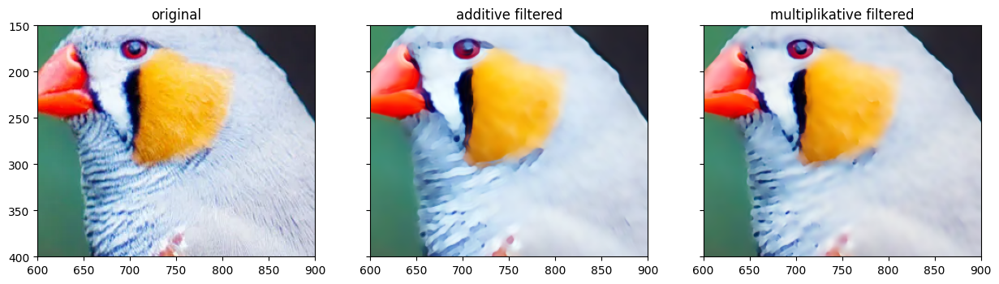

In [17]:
ax_table[0].set_xlim(600, 900)
ax_table[0].set_ylim(400, 150)

fig

#### Uteži uporabljene za združevanje filtrov - additivna mreža

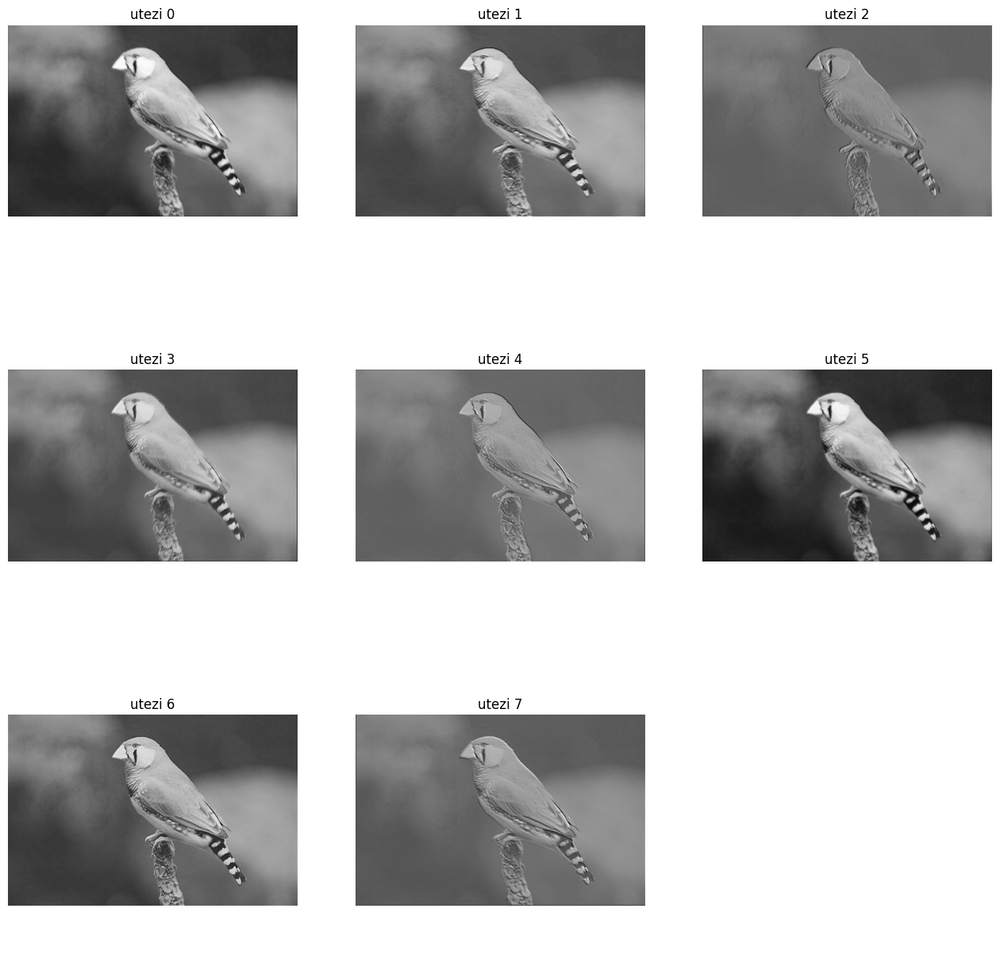

In [18]:
# Uteži
activation = {}

model_add.filterBranch.filter_conv_r.register_forward_hook(
    lambda model, input, output: activation.update({"filter_conv_r": output.detach()})
)

predictions = model_add(img_tr)
feature_maps = activation["filter_conv_r"].numpy()[0]

fig, ax_table = plt.subplots(3, 3, figsize=(16, 16), sharex=True, sharey=True)
ax_table = ax_table.ravel()

for n in range(8):
    ax_table[n].imshow(feature_maps[n], cmap='gray')
    ax_table[n].set_title(f'utezi {n}')
    ax_table[n].set_axis_off()

ax_table[8].set_axis_off()
plt.show()

#### Uteži uporabljene za združevanje filtrov - multiplikativna mreža

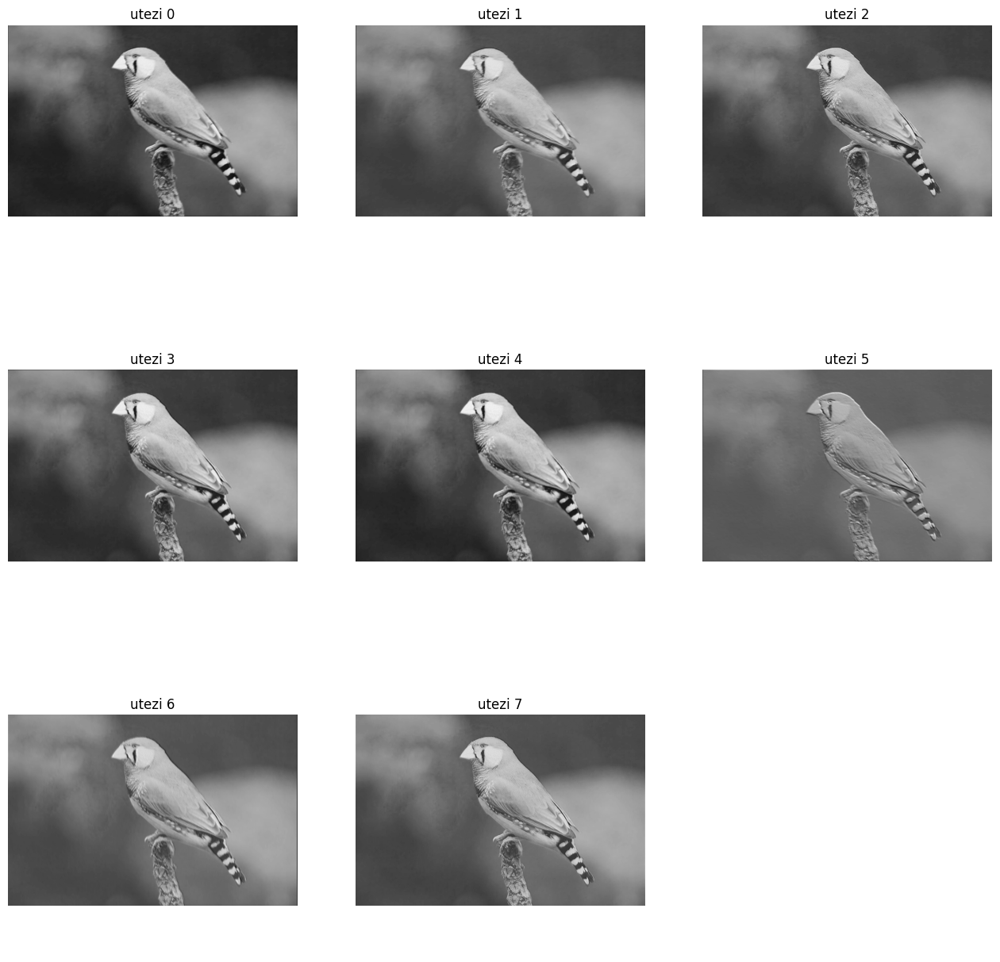

In [19]:
# Uteži
activation = {}

model_mul.filterBranch.filter_conv_r.register_forward_hook(
    lambda model, input, output: activation.update({"filter_conv_r": output.detach()})
)

predictions = model_mul(img_tr)
feature_maps = activation["filter_conv_r"].numpy()[0]

fig, ax_table = plt.subplots(3, 3, figsize=(16, 16), sharex=True, sharey=True)
ax_table = ax_table.ravel()

for n in range(8):
    ax_table[n].imshow(feature_maps[n], cmap='gray')
    ax_table[n].set_title(f'utezi {n}')
    ax_table[n].set_axis_off()

ax_table[8].set_axis_off()
plt.show()